# #103 Learning the Loop
Gradient Descent From Scratch
This notebook reproduces every figure and every number in article <br> **#103 — How Does a Model Actually Learn?**

# 1. load the real dataset

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()
x = diabetes.data[:, 2]   #BMI (standardized)
y = diabetes.target       #disease progression
n = len(x)

print(f"Loaded {n} real patients")
print(f"First 5 BMI values: {x[:5]}")
print(f"First 5 target values: {y[:5]}")

Loaded 442 real patients
First 5 BMI values: [ 0.06169621 -0.05147406  0.04445121 -0.01159501 -0.03638469]
First 5 target values: [151.  75. 141. 206. 135.]


# 2. implement gradient descent from scratch

In [10]:
def gradient_descent(x, y, lr, n_iter):
    w, b = 0.0, 0.0
    n = len(x)
    history_w, history_b, history_loss = [], [], []

    #predict
    for i in range(n_iter):
        y_pred = w * x + b

        #measure error
        error = y_pred - y
        loss = np.mean(error **2)

        #record history
        history_w.append(w)
        history_b.append(b)
        history_loss.append(loss)

        #early stopping
        if not np.isfinite(loss) or loss > 1e8:
            return history_w, history_b, history_loss, True

        #calculate gradients
        dw = (2 / n) * np.sum(error * x)
        db = (2 / n) * np.sum(error)

        #adjuest
        w -= lr * dw
        b -= lr * db
    return history_w, history_b, history_loss, False

#run with improved learning rate
ws, bs, losses, diverged = gradient_descent(x, y, lr=0.5, n_iter=60)

print(f"Loss at iteration 1: {losses[0]:.1f}")
print(f"Loss at iteration 60: {losses[-1]:.1f}")
print(f"Diverged: {diverged}")
        

Loss at iteration 1: 29074.5
Loss at iteration 60: 5451.6
Diverged: False


# 3. fitted line update in real time

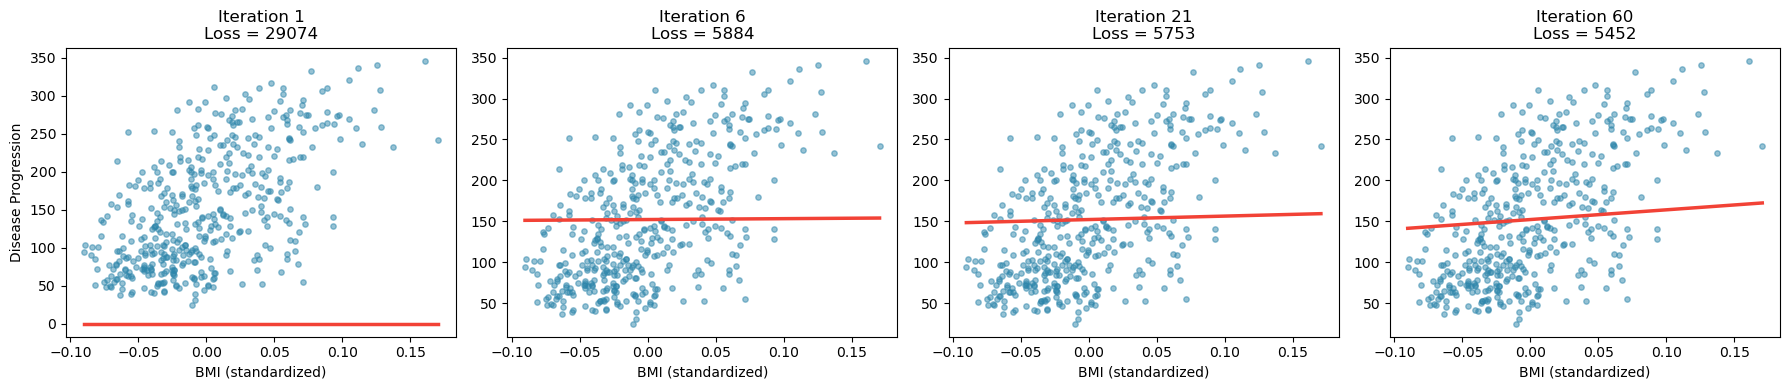

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
snapshot_iters = [0, 5, 20, 59]
x_line = np.linspace(x.min(), x.max(), 50)

for ax, i in zip(axes, snapshot_iters):
    ax.scatter(x, y, color="#2E86AB", s=15, alpha=0.5)
    ax.plot(
        x_line, 
        ws[i] * x_line + bs[i], 
        color="#F24236", 
        linewidth=2.5)
    ax.set_title(f"Iteration {i+1}\nLoss = {losses[i]:.0f}")
    ax.set_xlabel("BMI (standardized)")
    if ax is axes[0]:
        ax.set_ylabel("Disease Progression")

plt.tight_layout()
plt.show()

# the real loss

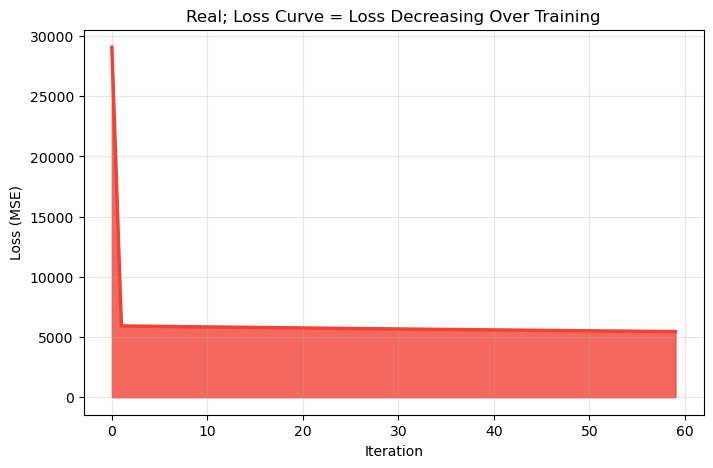

Loss fell from 29074.5 to 5451.6 over 60 real iterations


In [7]:
plt.figure(figsize=(8, 5))
plt.plot(losses, color="#F24236", linewidth=2.5)
plt.fill_between(range(len(losses)), losses, color="#F24236", alpha=0.8)
plt.xlabel("Iteration")
plt.ylabel("Loss (MSE)")
plt.title("Real; Loss Curve = Loss Decreasing Over Training")
plt.grid(alpha=0.3)
plt.show()

print(f"Loss fell from {losses[0]:.1f} to {losses[-1]:.1f} over {len(losses)} real iterations")

# proving the learning rate

In [12]:
results = []
for lr in [0.001, 0.5, 5.0]:
    weight_hist, bias_hist, losses_lr, diverged = gradient_descent(x, y, lr=lr, n_iter=60)
    final = "Diverged" if diverged else f"{losses_lr[-1]:.1f}"
    results.append((lr, final))
    print(f"Learning rate {lr:>6}: final loss after 60 iterations = {final}")

#closed form optimal solution
coeffs = np.polyfit(x, y, 1)
optimal_loss = np.mean((coeffs[0]*x + coeffs[1] - y) ** 2)
print(f"\nClosed form optimal loss: {optimal_loss:.1f}")
    

Learning rate  0.001: final loss after 60 iterations = 24203.6
Learning rate    0.5: final loss after 60 iterations = 5451.6
Learning rate    5.0: final loss after 60 iterations = Diverged

Closed form optimal loss: 3890.5


# You can Try

Things worth experimenting with, to build real intuition instead of just reading about it:

- Change `n_iter` from 60 to 200, does the `lr=0.5` run get closer to the closed-form optimal loss (3,890.5)?
- Try learning rates between 0.5 and 5.0 (e.g. 1.0, 2.0, 3.0), at what point does it start to diverge?
- Swap the feature from BMI (`diabetes.data[:, 2]`) to blood pressure (`diabetes.data[:, 3]`), does the same learning rate still work well?

**Data source:** Efron, B., Hastie, T., Johnstone, I., & Tibshirani, R. (2004). Least Angle Regression. Annals of Statistics, 32(2), 407–499.